In [54]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import torch
import trimesh

from hac.constants import OBSERVERS
from hac.data import get_model_folder, load_data
from hac.eval import relative_volume_difference_voxelized
from hac.lc2mesh.data import create_ellipsoidal_prior_mesh
from hac.lc2mesh.forward_model import AsteroidForwardModel, observers_to_unit_tensor
from hac.lc2mesh.metrics import compute_per_camera_metrics
from hac.lc2mesh.utils import set_seed, setup_device
from hac.lc2mesh.visualization import (
    plot_camera_grid,
    plot_interactive_mesh,
    plot_lightcurve_comparison,
)
from hac.mesh import normalize_mesh_to_challenge_cylinder

def facet_geometry(vertices: torch.Tensor, faces: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Facet normals [F,3] and areas [F] from vertices [V,3] (differentiable)."""
    tri = vertices[faces]  # [F, 3, 3]
    edge1 = tri[:, 1] - tri[:, 0]
    edge2 = tri[:, 2] - tri[:, 0]
    cross = torch.cross(edge1, edge2, dim=1)
    twice_area = cross.norm(dim=1)
    normals = cross / twice_area.clamp_min(1e-12).unsqueeze(1)
    return normals, 0.5 * twice_area

def predicted_lightcurves_from_mesh(vertices: torch.Tensor, faces: torch.Tensor) -> torch.Tensor:
    normals, areas = facet_geometry(vertices, faces)
    fm = AsteroidForwardModel(
        normals=normals,
        lambert_weight=LAMBERT_WEIGHT,
    )
    A = fm.build_forward_matrix(phases=phases, e_sun=e_sun, e_obs=e_obs)
    # AsteroidForwardModel computes in float32; match it so the einsum dtypes agree.
    raw = torch.einsum("cpf,f->cp", A.to(areas.dtype), areas)
    return raw / raw.mean(dim=1, keepdim=True).clamp_min(1e-12)

torch.set_default_dtype(torch.float64)


In [55]:
# --- Quick selector: choose asteroid + reconstruction variant ---
SELECTED_ASTEROID_ID = 10
PRIOR_SHAPE_TYPE = "ellipsoid"  # "ellipsoid", "peanut", "cube", "diamond" or "irregular"

if SELECTED_ASTEROID_ID not in list(range(1, 11)):
    raise ValueError(
        f"SELECTED_ASTEROID_ID must be in 1-10, got {SELECTED_ASTEROID_ID}"
    )
if PRIOR_SHAPE_TYPE not in {"ellipsoid", "peanut", "cube", "diamond", "irregular"}:
    raise ValueError(
        f"PRIOR_SHAPE_TYPE must be one of 'ellipsoid', 'peanut', 'cube', 'diamond', or 'irregular', got {PRIOR_SHAPE_TYPE!r}"
    )

print(f"Selected asteroid: {SELECTED_ASTEROID_ID}")
print(f"Prior shape type: {PRIOR_SHAPE_TYPE}")

Selected asteroid: 10
Prior shape type: ellipsoid


In [56]:
# --- Config + data loading ---
ASTEROID_ID = SELECTED_ASTEROID_ID
CURVE_TYPE = "intensity"
SEED = 42
TARGET_GPU_ID = 0
N_SUBDIVISIONS = 4
LAMBERT_WEIGHT = 0.3
TARGET_CAM = "135_hor1"

set_seed(SEED)
device = setup_device(TARGET_GPU_ID)

recon_dir = Path("recon")
recon_stl_file = recon_dir / f"stabilized_plain_ellipsoid_ast{ASTEROID_ID}_seed42.stl"

camera_names, e_obs = observers_to_unit_tensor(OBSERVERS, device=device, dtype=torch.float64)
e_sun = torch.tensor([-1.0, 0.0, 0.0], dtype=torch.float64, device=device)

ds_real = load_data(ASTEROID_ID, origin="real", curve_type=CURVE_TYPE)
observed = torch.as_tensor(
    ds_real.data[camera_names].to_numpy(dtype=np.float64, copy=True).T,
    dtype=torch.float64,
    device=device,
)
observed_norm = observed / observed.mean(dim=1, keepdim=True).clamp_min(1e-12)
n_phase = observed.shape[1]
phases = torch.arange(n_phase, dtype=torch.float64, device=device) * (2.0 * torch.pi / n_phase)

prior = create_ellipsoidal_prior_mesh(
    asteroid_id=ASTEROID_ID, subdivisions=N_SUBDIVISIONS, device=device, shape_type=PRIOR_SHAPE_TYPE
)
R_CYL = float(prior["R_CYLINDER"])

if not recon_stl_file.exists():
    raise FileNotFoundError(f"Reconstruction STL not found: {recon_stl_file.resolve()}")

recon_mesh_raw = trimesh.load_mesh(recon_stl_file)
recon_mesh = normalize_mesh_to_challenge_cylinder(recon_mesh_raw, R_CYL)
recon_vertices = torch.as_tensor(recon_mesh.vertices, dtype=torch.float64, device=device)
recon_faces = torch.as_tensor(recon_mesh.faces, dtype=torch.long, device=device)

model_dir = get_model_folder(ASTEROID_ID)
gt_stl_file = model_dir / f"asteroid{ASTEROID_ID}.stl"
GT_EXIST = gt_stl_file.exists()
true_mesh = None
if GT_EXIST:
    true_mesh = normalize_mesh_to_challenge_cylinder(trimesh.load_mesh(gt_stl_file), R_CYL)
else:
    print(f"Warning: GT STL file not found at {gt_stl_file}")

print(f"Asteroid {ASTEROID_ID}: cameras={len(camera_names)}, phases={n_phase}")
print(f"Reconstruction STL: {recon_stl_file.resolve()}")
print(f"Cylinder radius: {R_CYL:.3f}")

pred_norm = predicted_lightcurves_from_mesh(recon_vertices, recon_faces)
per_camera_df = compute_per_camera_metrics(observed_norm, pred_norm, camera_names)

Device: cuda:0 (Tesla V100-SXM2-32GB)
Visible CUDA devices: 8
Asteroid 10: cameras=28, phases=841
Reconstruction STL: /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/recon/stabilized_plain_ellipsoid_ast10_seed42.stl
Cylinder radius: 3.950


In [57]:
# --- Reconstruction mesh visualization + GT comparison ---
fig_mesh = plot_interactive_mesh(
    vertices=recon_mesh.vertices,
    faces=recon_mesh.faces,
    title=(
        f"Asteroid {ASTEROID_ID}: reconstructed mesh ({recon_mesh.faces.shape[0]} faces) | "
        f"mean_r={per_camera_df['Pearson_R'].mean():.3f}"
    ),
    mesh_color="#c0b08a",
    show_edges=False,
)
fig_mesh.show()

if GT_EXIST and true_mesh is not None:
    gt_fig_mesh = plot_interactive_mesh(
        vertices=true_mesh.vertices,
        faces=true_mesh.faces,
        title=f"Asteroid {ASTEROID_ID}: GT mesh, cylinder-normalized ({true_mesh.faces.shape[0]} faces)",
        mesh_color="#a0c0ff",
        show_edges=False,
    )
    gt_fig_mesh.show()

print(
    f"Reconstruction extents: "
    f"x[{recon_mesh.vertices[:, 0].min():.3f}, {recon_mesh.vertices[:, 0].max():.3f}] "
    f"y[{recon_mesh.vertices[:, 1].min():.3f}, {recon_mesh.vertices[:, 1].max():.3f}] "
    f"z[{recon_mesh.vertices[:, 2].min():.3f}, {recon_mesh.vertices[:, 2].max():.3f}] "
    f"(cylinder bound: R={R_CYL}, z in [-1, 1])"
)

if GT_EXIST and true_mesh is not None:
    print(
        f"GT extents: "
        f"x[{true_mesh.vertices[:, 0].min():.3f}, {true_mesh.vertices[:, 0].max():.3f}] "
        f"y[{true_mesh.vertices[:, 1].min():.3f}, {true_mesh.vertices[:, 1].max():.3f}] "
        f"z[{true_mesh.vertices[:, 2].min():.3f}, {true_mesh.vertices[:, 2].max():.3f}]"
    )
    pred_mesh = trimesh.Trimesh(vertices=recon_mesh.vertices, faces=recon_mesh.faces, process=False)
    VOXEL_PITCH = 0.05  # official filled-voxel measure, pitch on cylinder-normalized meshes
    measure1, measure2 = relative_volume_difference_voxelized(pred_mesh, true_mesh, pitch=VOXEL_PITCH)
    print(f"Official voxel measures vs GT (pitch={VOXEL_PITCH}); 0 = identical, lower is better:")
    print(f"  measure1 (1 - IoU)={measure1:.6f} | measure2 (sym-diff/sum)={measure2:.6f}")
else:
    print("GT mesh not available -> skipping voxel measure calculation.")


Reconstruction extents: x[-3.512, 3.512] y[-3.153, 3.153] z[-1.000, 1.000] (cylinder bound: R=3.95, z in [-1, 1])
GT mesh not available -> skipping voxel measure calculation.


Final lightcurve fit: mean_r=0.8271, min_r=0.6695, mean MSE=0.032589


,MSE,MAE,Pearson_R
Camera,,,
225_hor2,0.131966,0.282162,0.669487
315_bottom,0.015870,0.098342,0.671504
225_hor1,0.114891,0.258418,0.693483
135_hor1,0.120160,0.287971,0.716649
135_hor2,0.103667,0.254980,0.752878
315_top,0.013509,0.092222,0.758382
0_bottom,0.020496,0.114818,0.772203
45_bottom,0.016488,0.100043,0.797537
315_hor2,0.030982,0.157962,0.805439


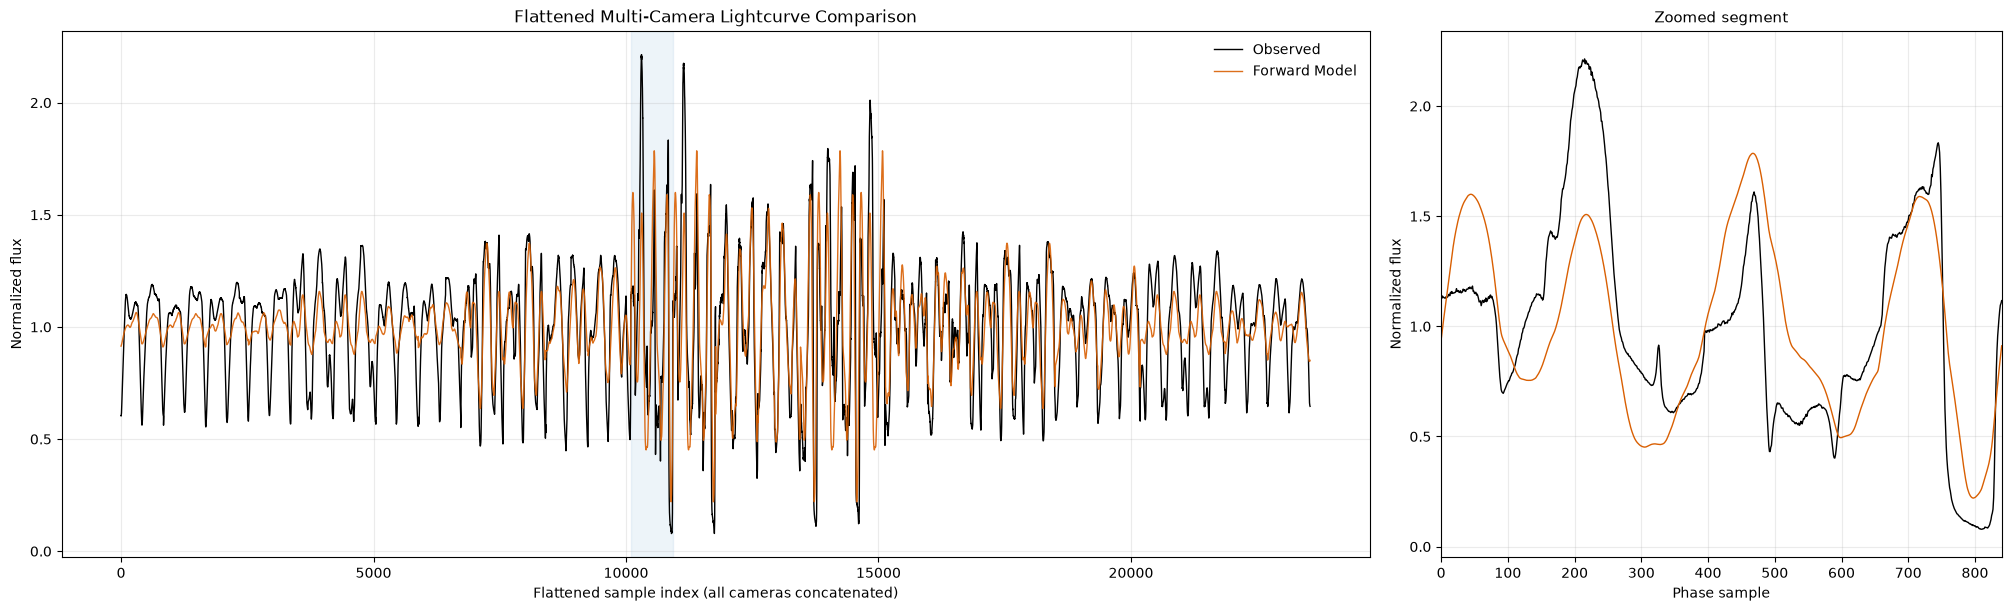

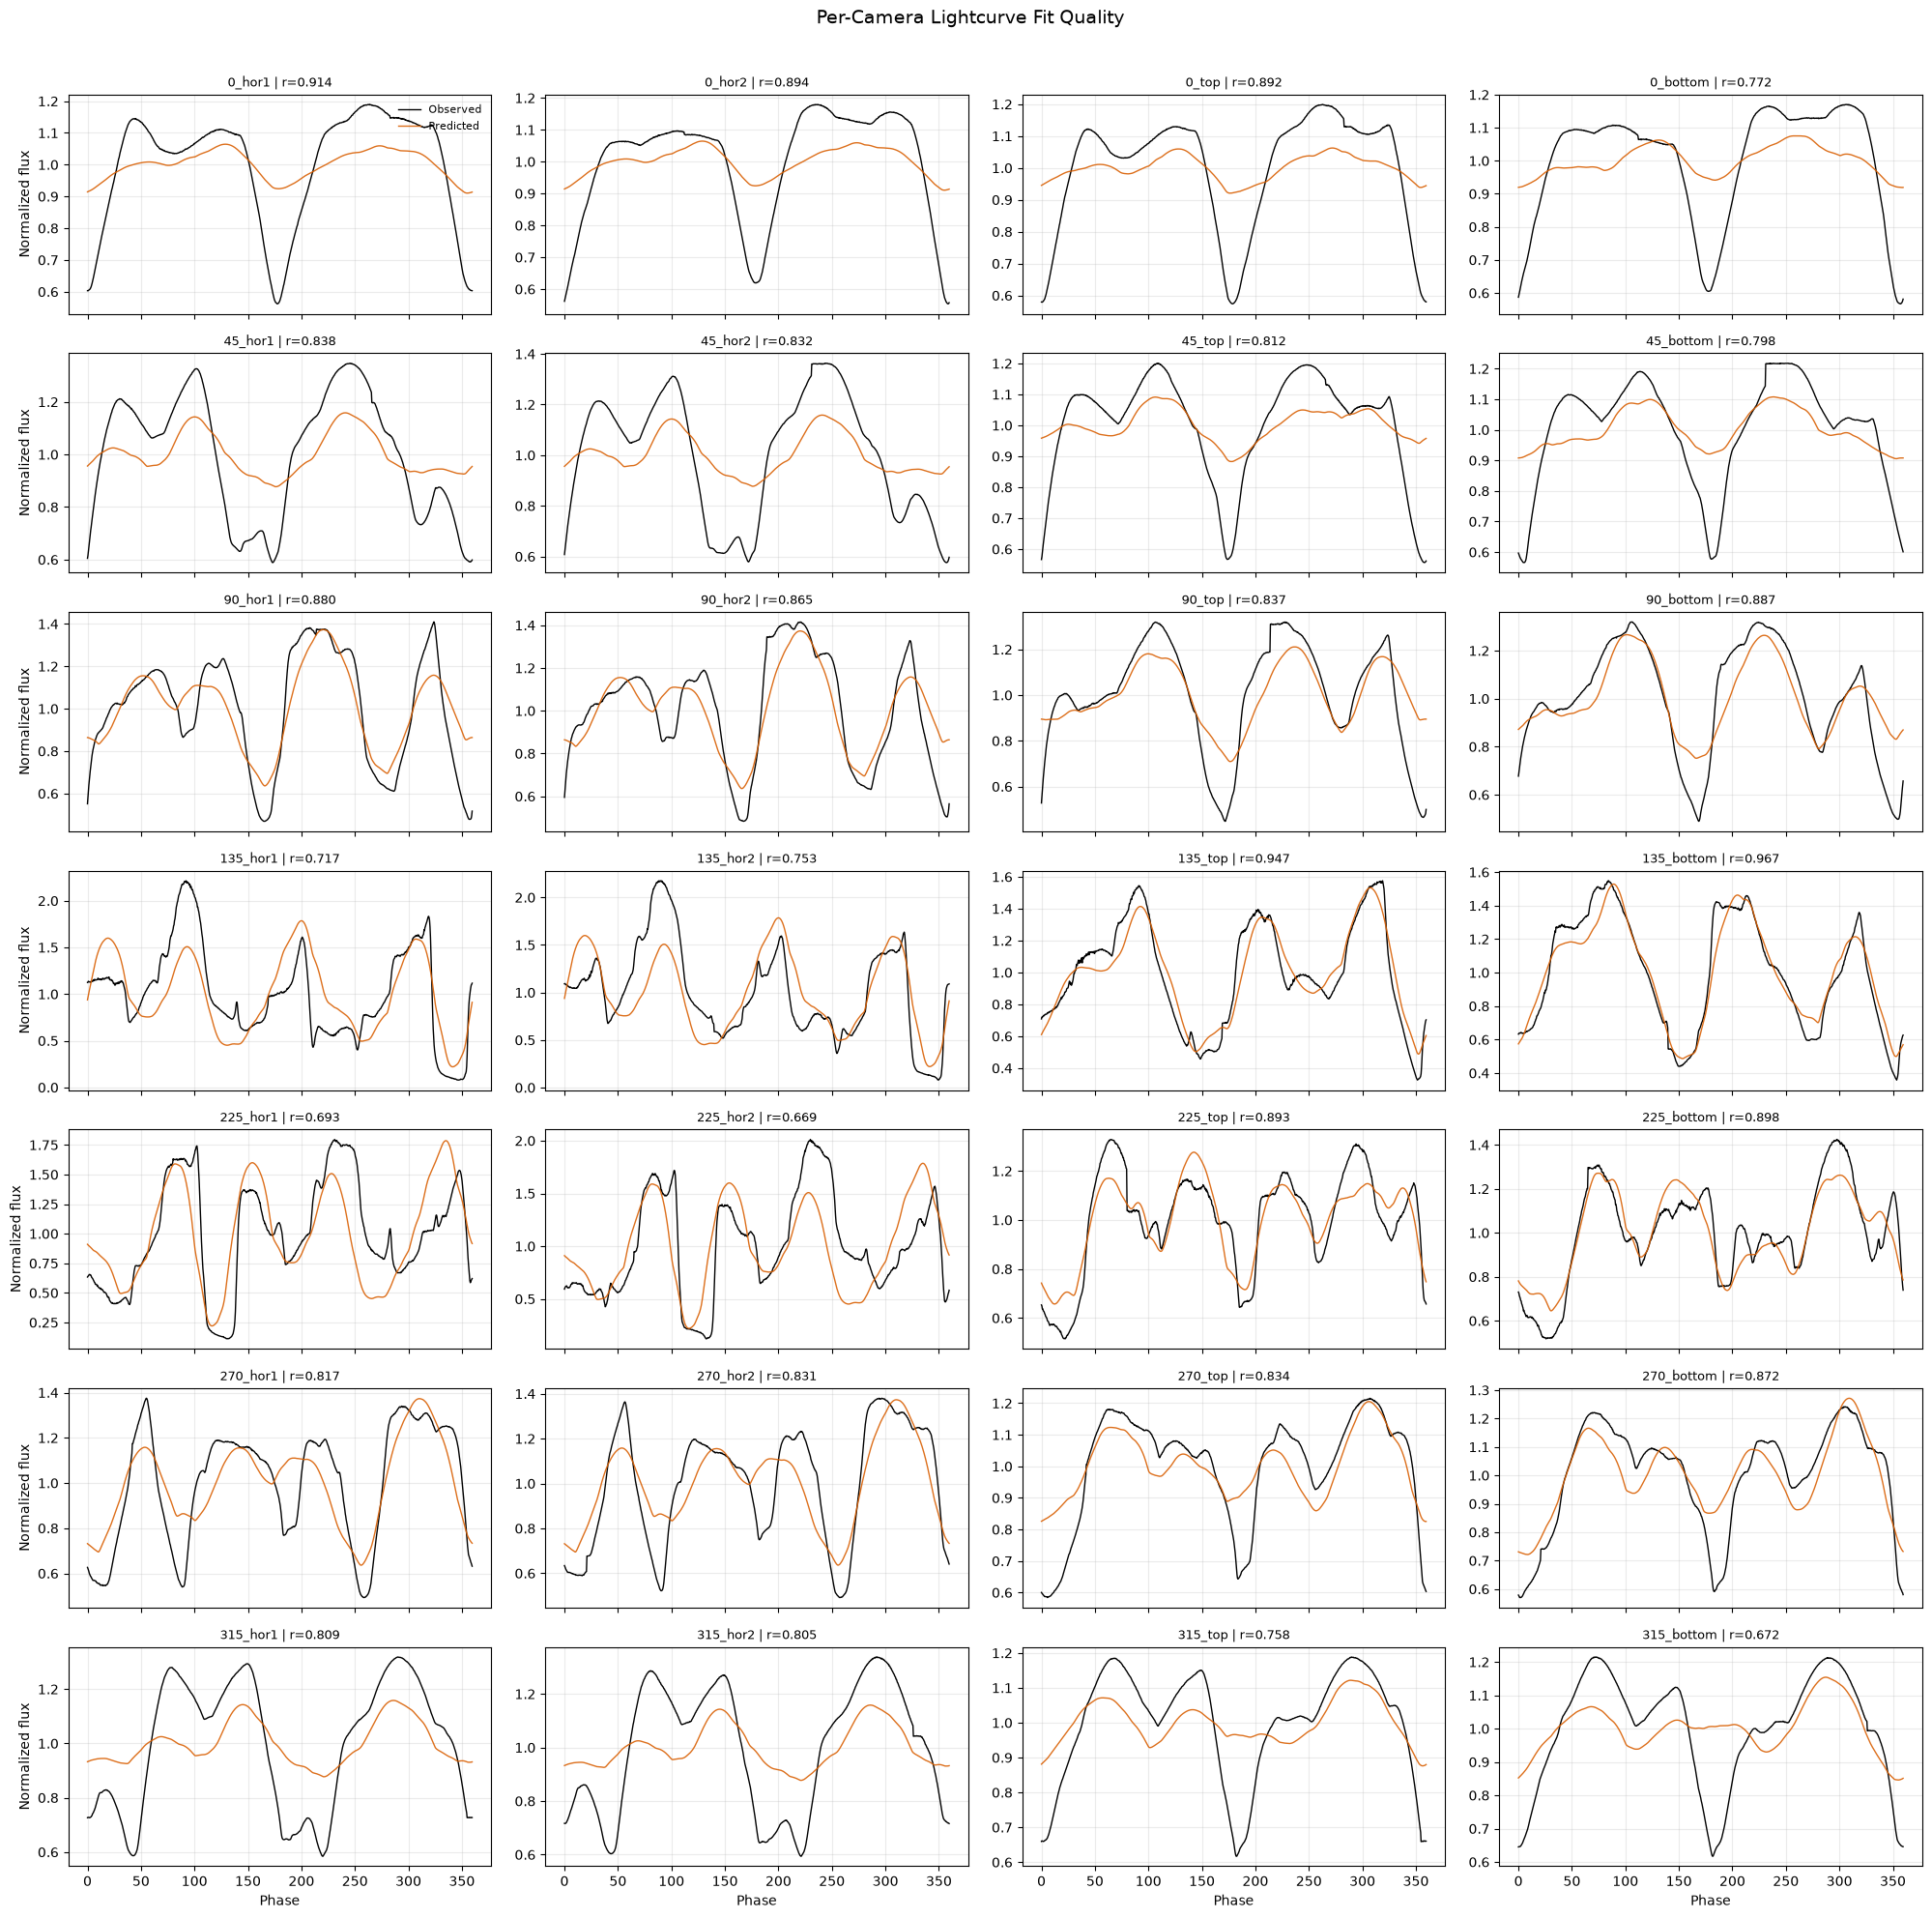

In [58]:
# --- Lightcurve comparison plots ---

print(
    f"Final lightcurve fit: mean_r={per_camera_df['Pearson_R'].mean():.4f}, "
    f"min_r={per_camera_df['Pearson_R'].min():.4f}, "
    f"mean MSE={per_camera_df['MSE'].mean():.6f}"
)
display(per_camera_df.sort_values("Pearson_R"))

target_cam = TARGET_CAM if TARGET_CAM in camera_names else camera_names[0]
fig, _ = plot_lightcurve_comparison(
    obs_norm=observed_norm.detach().cpu().numpy(),
    pred_norm=pred_norm.detach().cpu().numpy(),
    camera_keys=camera_names,
    target_cam_id=target_cam,
)
plt.show()

phase_deg = np.rad2deg(phases.detach().cpu().numpy())
fig, _ = plot_camera_grid(observed_norm, pred_norm, camera_names, phase_axis=phase_deg)
plt.show()

In [59]:
# --- Rotating video: reconstruction (+ target GT if available) ---
import io

from matplotlib import colors as mcolors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import imageio.v2 as imageio
from IPython.display import Video

VIDEO_DIR = Path("videos")
VIDEO_DIR.mkdir(exist_ok=True)
N_FRAMES = 60          # 6 s at 10 fps
FPS = 10
ELEV = 20.0            # camera elevation (degrees)
BG_COLOR = "white"     # set to "black" to match a dark-background reference
RECON_COLOR = "#c0b08a"
TARGET_COLOR = "#a0c0ff"
# matplotlib depth-sorts every triangle per frame; the raw GT STL is ~800k faces,
# so decimate display meshes. This is render-only and does not touch the metrics above.
MAX_DISPLAY_FACES = 20000


def _display_mesh(mesh):
    """Decimate a high-poly mesh for fast matplotlib rendering (visual only)."""
    if len(mesh.faces) <= MAX_DISPLAY_FACES:
        return mesh
    try:
        return mesh.simplify_quadric_decimation(face_count=MAX_DISPLAY_FACES)
    except Exception as exc:  # no decimation backend -> fall back to the full mesh
        print(f"  (decimation unavailable: {exc}; rendering full {len(mesh.faces)} faces)")
        return mesh


def _shaded_facecolors(vertices, faces, base_hex, light_dir=(0.4, 0.3, 1.0), ambient=0.5, diffuse=0.5):
    """Fixed-light Lambert shading so the rotating mesh reads as a solid object."""
    tri = vertices[faces]
    normals = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    normals /= np.linalg.norm(normals, axis=1, keepdims=True) + 1e-12
    light = np.asarray(light_dir, dtype=float)
    light /= np.linalg.norm(light)
    shade = ambient + diffuse * np.clip(normals @ light, 0.0, 1.0)
    base = np.asarray(mcolors.to_rgb(base_hex))
    return np.clip(shade[:, None] * base[None, :], 0.0, 1.0)


def _add_mesh(ax, mesh, base_hex, lim):
    vertices = np.asarray(mesh.vertices)
    faces = np.asarray(mesh.faces)
    collection = Poly3DCollection(
        vertices[faces],
        facecolors=_shaded_facecolors(vertices, faces, base_hex),
        edgecolors="none",
    )
    ax.add_collection3d(collection)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_zlim(-lim, lim)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.set_facecolor(BG_COLOR)


panels = [("Reconstruction", recon_mesh, RECON_COLOR)]
if GT_EXIST and true_mesh is not None:
    panels = [("Target", true_mesh, TARGET_COLOR), ("Reconstruction", recon_mesh, RECON_COLOR)]
panels = [(name, _display_mesh(mesh), color) for name, mesh, color in panels]

title_color = "white" if BG_COLOR == "black" else "black"
lim = max(R_CYL, 1.0) * 1.05
fig = plt.figure(figsize=(6 * len(panels), 6), facecolor=BG_COLOR)
axes = []
for index, (name, mesh, color) in enumerate(panels):
    ax = fig.add_subplot(1, len(panels), index + 1, projection="3d")
    ax.set_title(f"Asteroid {ASTEROID_ID}: {name}", color=title_color)
    _add_mesh(ax, mesh, color, lim)
    axes.append(ax)

suffix = "true_vs_optimized" if len(panels) == 2 else "reconstruction"
video_path = VIDEO_DIR / f"{suffix}_ast{ASTEROID_ID}.mp4"

# Force the ffmpeg backend and a broadly-compatible pixel format.
writer = imageio.get_writer(
    video_path, format="FFMPEG", fps=FPS, codec="libx264",
    macro_block_size=16, output_params=["-pix_fmt", "yuv420p"],
)
for frame_index in range(N_FRAMES):
    azim = 360.0 * frame_index / N_FRAMES
    for ax in axes:
        ax.view_init(elev=ELEV, azim=azim)
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", facecolor=fig.get_facecolor(), dpi=100)
    buffer.seek(0)
    writer.append_data(imageio.imread(buffer)[..., :3])
writer.close()
plt.close(fig)

print(f"Saved rotating video ({N_FRAMES} frames @ {FPS} fps): {video_path.resolve()}")
Video(str(video_path), embed=True)


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (600, 600) to (608, 608) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
Multiple -pix_fmt options specified for stream 0, only the last option '-pix_fmt yuv420p' will be used.


Saved rotating video (60 frames @ 10 fps): /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/videos/reconstruction_ast10.mp4
